In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn requests

Defaulting to user installation because normal site-packages is not writeable
Looking in links: /usr/share/pip-wheels
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
print("pandas works:", pd.__version__)

pandas works: 1.4.2


In [8]:
import re
import requests
import numpy as np
import pandas as pd
from pathlib import Path

# Folders
for p in ["data/raw", "data/processed", "reports/figures", "src"]:
    Path(p).mkdir(parents=True, exist_ok=True)

urls = {
    "wheat_production": "https://opendata.com.pk/datastore/dump/8f805abc-56c7-40d1-a2c1-708f31157479?bom=True",
    "wheat_area": "https://opendata.com.pk/datastore/dump/9b9f1869-834d-4fda-b9fc-5b6b73ac41b4?bom=True",
}
headers = {"User-Agent": "Mozilla/5.0"}

for name, url in urls.items():
    out = Path(f"data/raw/{name}.csv")
    if out.exists():
        print("Already have", name)
        continue
    try:
        r = requests.get(url, headers=headers, timeout=60)
        r.raise_for_status()
        out.write_text(r.content.decode("utf-8-sig"), encoding="utf-8")
        print("Downloaded", name, len(r.content), "bytes")
    except Exception as e:
        print("FAILED", name, "->", repr(e))

# Quick look at what we got
for name in urls:
    f = Path(f"data/raw/{name}.csv")
    if f.exists():
        df = pd.read_csv(f)
        print("\n", name, df.shape)
        display(df.head(3))

Already have wheat_production
Already have wheat_area

 wheat_production (47, 14)


,Province/division\n/district,2007-08,2008-09,2009-10,2010-11,2011-12,2012-13,2013-14,2014-15,2015-16,2016-17,2017-18,2018-19,2019-20
0,PUNJAB,"15,607","18,420","17,919","19,041","17,739","18,585","19,739","19,282","19,527","20,466","19,179","18,377","19,402"
1,Bahawalpur Div.,"2,274","2,745","2,832","2,901","2,713","2,728","2,960","3,092","3,117","3,157","2,872","3,044","3,512"
2,Bahawalnagar,835,990,"1,059","1,077",989,"1,002","1,090","1,161","1,132","1,218","1,133","1,158","1,504"



 wheat_area (47, 14)


,Province/division\n/district,2007-08,2008-09,2009-10,2010-11,2011-12,2012-13,2013-14,2014-15,2015-16,2016-17,2017-18,2018-19,2019-20
0,PUNJAB,"6,403","6,835","6,914","6,691","6,483","6,511","6,903","6,980","6,915","6,661","6,560","6,496","6,515"
1,Bahawalpur Div.,905,962,991,927,884,880,943,991,980,941,930,964,996
2,Bahawalnagar,326,346,354,345,336,336,359,369,371,373,369,357,405


In [9]:
def load_clean(path, value_name):
    raw = pd.read_csv(path)
    raw = raw.drop(columns=[c for c in raw.columns if c == "_id"])
    raw = raw.rename(columns={raw.columns[0]: "district"})
    raw["district"] = raw["district"].astype(str).str.strip()

    drop_mask = raw["district"].str.contains(
        r"\bdiv(?:ision)?\b|^punjab$|total|^islamabad", case=False, regex=True
    )
    dropped = raw.loc[drop_mask, "district"].tolist()
    df = raw.loc[~drop_mask].copy()

    year_cols = [c for c in df.columns if re.match(r"\d{4}-\d{2}", str(c))]
    for c in year_cols:
        df[c] = pd.to_numeric(
            df[c].astype(str).str.replace(",", "", regex=False).str.strip(),
            errors="coerce",
        )
    long = df.melt(id_vars="district", value_vars=year_cols,
                   var_name="season", value_name=value_name)
    long["harvest_year"] = long["season"].str[:4].astype(int) + 1   # 2007-08 -> harvest 2008
    return long, dropped

prod, dropped_p = load_clean("data/raw/wheat_production.csv", "production_1000t")
area, dropped_a = load_clean("data/raw/wheat_area.csv", "area_1000ha")

print("Rows removed (production):", dropped_p)
print("Rows removed (area):", dropped_a)
print("Districts kept:", prod["district"].nunique(), "/", area["district"].nunique(), "(expect 36 / 36)")
print("Names in one file but not the other:",
      set(prod["district"]) ^ set(area["district"]))

panel = prod.merge(area, on=["district", "season", "harvest_year"], how="inner")
panel["yield_kg_ha"] = panel["production_1000t"] / panel["area_1000ha"] * 1000
panel.to_csv("data/processed/wheat_panel.csv", index=False)

print("\nPanel shape:", panel.shape, "(expect 468 rows = 36 districts x 13 years)")
print("Missing production / area / yield:",
      panel["production_1000t"].isna().sum(),
      panel["area_1000ha"].isna().sum(),
      panel["yield_kg_ha"].isna().sum())
print(panel["yield_kg_ha"].describe().round(0))

print("\nLowest 5 yields:")
display(panel.nsmallest(5, "yield_kg_ha")[["district", "harvest_year", "production_1000t", "area_1000ha", "yield_kg_ha"]].round(0))
print("Highest 5 yields:")
display(panel.nlargest(5, "yield_kg_ha")[["district", "harvest_year", "production_1000t", "area_1000ha", "yield_kg_ha"]].round(0))

Rows removed (production): ['PUNJAB', 'Bahawalpur Div.', 'D.G.Khan Div.', 'Faisalabad Div.', 'Gujranwala Div.', 'Lahore Division', 'Multan Division', 'Rawalpindi Div.', 'Sahiwal Division', 'Sargodha Div.', 'Islamabad']
Rows removed (area): ['PUNJAB', 'Bahawalpur Div.', 'D.G.Khan Division', 'Faisalabad Div.', 'Gujranwala Div.', 'Lahore Division', 'Multan Division', 'Rawalpindi Div.', 'Sahiwal Division', 'Sargodha Div.', 'Islamabad']
Districts kept: 36 / 36 (expect 36 / 36)
Names in one file but not the other: set()

Panel shape: (468, 6) (expect 468 rows = 36 districts x 13 years)
Missing production / area / yield: 2 2 2
count     466.0
mean     2719.0
std       696.0
min       612.0
25%      2360.0
50%      2887.0
75%      3151.0
max      8906.0
Name: yield_kg_ha, dtype: float64

Lowest 5 yields:


,district,harvest_year,production_1000t,area_1000ha,yield_kg_ha
98,Chakwal,2010,41.0,67.0,612.0
90,Lahore,2010,164.0,210.0,781.0
100,Rawalpindi,2010,88.0,98.0,898.0
170,Chakwal,2012,113.0,122.0,926.0
97,Attock,2010,143.0,146.0,979.0


Highest 5 yields:


,district,harvest_year,production_1000t,area_1000ha,yield_kg_ha
89,Kasur,2010,570.0,64.0,8906.0
346,Lodhran,2017,797.0,205.0,3888.0
463,Pakpattan,2020,363.0,96.0,3781.0
139,Pakpattan,2011,555.0,147.0,3776.0
345,Khanewal,2017,754.0,200.0,3770.0


In [10]:
panel = pd.read_csv("data/processed/wheat_panel.csv")

print("Rows with missing values:")
display(panel[panel["yield_kg_ha"].isna()]
        [["district", "harvest_year", "production_1000t", "area_1000ha"]])

for d in ["Kasur", "Lahore"]:
    print(f"\n{d} across all years:")
    display(panel[panel["district"] == d]
            .set_index("harvest_year")[["production_1000t", "area_1000ha", "yield_kg_ha"]]
            .round(0).T)

# Systematic check: yields far from the district's own median
ratio = panel["yield_kg_ha"] / panel.groupby("district")["yield_kg_ha"].transform("median")
print("\nYields below 0.5x or above 1.6x the district's own median:")
display(panel.loc[(ratio < 0.5) | (ratio > 1.6),
        ["district", "harvest_year", "production_1000t", "area_1000ha", "yield_kg_ha"]]
        .assign(ratio=ratio.round(2)).round(0))

# Flag the Kasur 2010 error (kept in the table but set to missing, with a note)
panel["yield_flag"] = ""
mask = (panel["district"] == "Kasur") & (panel["harvest_year"] == 2010)
panel.loc[mask, "yield_flag"] = "suspect_outlier"
panel.loc[mask, "yield_kg_ha"] = np.nan

panel.to_csv("data/processed/wheat_panel_clean.csv", index=False)
print("\nMissing yield values now:", panel["yield_kg_ha"].isna().sum(), "(expect 3)")
print("Max yield now:", round(panel["yield_kg_ha"].max()))

Rows with missing values:


,district,harvest_year,production_1000t,area_1000ha
8,Chiniot,2008,NaN,NaN
44,Chiniot,2009,NaN,NaN



Kasur across all years:


harvest_year,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
production_1000t,486.0,577.0,570.0,578.0,570.0,536.0,548.0,514.0,479.0,527.0,514.0,467.0,478.0
area_1000ha,180.0,194.0,64.0,187.0,184.0,179.0,182.0,168.0,166.0,164.0,163.0,162.0,132.0
yield_kg_ha,2700.0,2974.0,8906.0,3091.0,3098.0,2994.0,3011.0,3060.0,2886.0,3213.0,3153.0,2883.0,3621.0



Lahore across all years:


harvest_year,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
production_1000t,142.0,156.0,164.0,186.0,192.0,177.0,174.0,164.0,170.0,181.0,172.0,167.0,148.0
area_1000ha,58.0,62.0,210.0,65.0,64.0,57.0,59.0,60.0,57.0,58.0,55.0,53.0,41.0
yield_kg_ha,2448.0,2516.0,781.0,2862.0,3000.0,3105.0,2949.0,2733.0,2982.0,3121.0,3127.0,3151.0,3610.0



Yields below 0.5x or above 1.6x the district's own median:


,district,harvest_year,production_1000t,area_1000ha,yield_kg_ha,ratio
89,Kasur,2010,570.0,64.0,8906.0,3.0
90,Lahore,2010,164.0,210.0,781.0,0.0
98,Chakwal,2010,41.0,67.0,612.0,0.0



Missing yield values now: 3 (expect 3)
Max yield now: 3888


In [11]:
panel = pd.read_csv("data/processed/wheat_panel_clean.csv")

# Compare the low 2010 values against each district's own history
for d in ["Chakwal", "Rawalpindi", "Attock"]:
    print(f"\n{d}:")
    display(panel[panel["district"] == d]
            .set_index("harvest_year")[["production_1000t", "area_1000ha", "yield_kg_ha"]]
            .round(0).T)

# Ratio to each district's own median, with 2 decimals this time
panel["ratio_to_median"] = panel["yield_kg_ha"] / panel.groupby("district")["yield_kg_ha"].transform("median")
print("\nDistrict-years below 0.6x or above 1.5x their own median:")
display(panel.loc[(panel["ratio_to_median"] < 0.6) | (panel["ratio_to_median"] > 1.5),
        ["district", "harvest_year", "production_1000t", "area_1000ha", "yield_kg_ha", "ratio_to_median"]]
        .round({"production_1000t": 0, "area_1000ha": 0, "yield_kg_ha": 0, "ratio_to_median": 2}))

# Flag Lahore 2010 too (area value is clearly wrong: 210 vs about 60 in every other year)
mask = (panel["district"] == "Lahore") & (panel["harvest_year"] == 2010)
panel.loc[mask, "yield_flag"] = "suspect_outlier"
panel.loc[mask, "yield_kg_ha"] = np.nan

panel = panel.drop(columns="ratio_to_median")
panel.to_csv("data/processed/wheat_panel_clean.csv", index=False)
print("\nMissing yield values now:", panel["yield_kg_ha"].isna().sum(), "(expect 4: Chiniot x2, Kasur, Lahore)")
print("Rows with yield:", panel["yield_kg_ha"].notna().sum(), "(expect 464)")


Chakwal:


harvest_year,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
production_1000t,137.0,169.0,41.0,166.0,113.0,192.0,158.0,198.0,234.0,143.0,129.0,160.0,266.0
area_1000ha,122.0,129.0,67.0,126.0,122.0,118.0,120.0,119.0,130.0,115.0,116.0,120.0,155.0
yield_kg_ha,1123.0,1310.0,612.0,1317.0,926.0,1627.0,1317.0,1664.0,1800.0,1243.0,1112.0,1333.0,1716.0



Rawalpindi:


harvest_year,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
production_1000t,175.0,208.0,88.0,158.0,144.0,211.0,165.0,179.0,184.0,120.0,156.0,162.0,230.0
area_1000ha,109.0,115.0,98.0,115.0,117.0,116.0,117.0,111.0,110.0,97.0,104.0,104.0,151.0
yield_kg_ha,1606.0,1809.0,898.0,1374.0,1231.0,1819.0,1410.0,1613.0,1673.0,1237.0,1500.0,1558.0,1523.0



Attock:


harvest_year,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
production_1000t,200.0,275.0,143.0,253.0,167.0,165.0,218.0,301.0,335.0,205.0,223.0,287.0,331.0
area_1000ha,157.0,161.0,146.0,156.0,155.0,156.0,159.0,174.0,188.0,151.0,151.0,151.0,201.0
yield_kg_ha,1274.0,1708.0,979.0,1622.0,1077.0,1058.0,1371.0,1730.0,1782.0,1358.0,1477.0,1901.0,1647.0



District-years below 0.6x or above 1.5x their own median:


,district,harvest_year,production_1000t,area_1000ha,yield_kg_ha,ratio_to_median
90,Lahore,2010,164.0,210.0,781.0,0.26
98,Chakwal,2010,41.0,67.0,612.0,0.46
100,Rawalpindi,2010,88.0,98.0,898.0,0.59



Missing yield values now: 4 (expect 4: Chiniot x2, Kasur, Lahore)
Rows with yield: 464 (expect 464)


In [12]:
import time

coords = {
    "Bahawalnagar": (29.9987, 73.2536), "Bahawalpur": (29.3956, 71.6836),
    "Rahim Yar Khan": (28.4202, 70.2952), "D.G.Khan": (30.0489, 70.6455),
    "Layyah": (30.9693, 70.9428), "Muzaffargarh": (30.0703, 71.1933),
    "Rajanpur": (29.1044, 70.3250), "Faisalabad": (31.4504, 73.1350),
    "Chiniot": (31.7292, 72.9788), "Jhang": (31.2681, 72.3181),
    "T.T.Singh": (30.9709, 72.4826), "Gujranwala": (32.1877, 74.1945),
    "Gujrat": (32.5731, 74.0754), "Hafizabad": (32.0709, 73.6880),
    "Mandi Baha-ud-Din": (32.5742, 73.4912), "Narowal": (32.1019, 74.8730),
    "Sialkot": (32.4945, 74.5229), "Kasur": (31.1187, 74.4467),
    "Lahore": (31.5497, 74.3436), "Nankana Sahib": (31.4492, 73.7120),
    "Sheikhupura": (31.7167, 73.9850), "Khanewal": (30.3017, 71.9321),
    "Lodhran": (29.5339, 71.6324), "Multan": (30.1575, 71.5249),
    "Vehari": (30.0452, 72.3489), "Attock": (33.7660, 72.3609),
    "Chakwal": (32.9328, 72.8630), "Jhelum": (32.9425, 73.7257),
    "Rawalpindi": (33.5651, 73.0169), "Sahiwal": (30.6682, 73.1114),
    "Okara": (30.8138, 73.4534), "Pakpattan": (30.3431, 73.3894),
    "Bhakkar": (31.6082, 71.0854), "Khushab": (32.2953, 72.3489),
    "Mianwali": (32.5839, 71.5370), "Sargodha": (32.0836, 72.6711),
}

panel = pd.read_csv("data/processed/wheat_panel_clean.csv")
print("Districts without coordinates:", set(panel["district"]) - set(coords))   # expect set()
print("Coordinates without a district:", set(coords) - set(panel["district"]))  # expect set()

out_file = Path("data/raw/weather_monthly_long.csv")
if out_file.exists():
    print("Weather file already exists, skipping download.")
else:
    params = "PRECTOTCORR,T2M,T2M_MAX,T2M_MIN,ALLSKY_SFC_SW_DWN"
    rows, failed = [], []
    for i, (name, (lat, lon)) in enumerate(coords.items(), 1):
        url = ("https://power.larc.nasa.gov/api/temporal/monthly/point"
               f"?parameters={params}&community=AG&longitude={lon}&latitude={lat}"
               "&start=2007&end=2020&format=JSON")
        for attempt in range(3):
            try:
                r = requests.get(url, timeout=60)
                r.raise_for_status()
                data = r.json()["properties"]["parameter"]
                break
            except Exception as e:
                print("  retry", name, repr(e)[:80])
                time.sleep(3)
        else:
            failed.append(name)
            continue
        for var, series in data.items():
            for ym, val in series.items():
                year, month = int(ym[:4]), int(ym[4:])
                if month <= 12:            # month 13 = annual average, skip
                    rows.append((name, year, month, var, val))
        print(f"{i}/36 done: {name}")

    weather = pd.DataFrame(rows, columns=["district", "year", "month", "variable", "value"])
    weather["value"] = weather["value"].replace(-999, np.nan)   # -999 means missing
    weather.to_csv(out_file, index=False)
    print("\nFailed districts:", failed)

weather = pd.read_csv(out_file)
print("\nShape:", weather.shape, "(expect 30240 x 5 = 36 districts x 14 years x 12 months x 5 variables)")
print("Districts:", weather["district"].nunique(), "| Missing values:", int(weather["value"].isna().sum()))
print("Years:", weather["year"].min(), "-", weather["year"].max())

# Drought check for the Pothohar districts: Nov-Apr rainfall (mm/day) by harvest year
chk = weather[(weather["variable"] == "PRECTOTCORR") &
              (weather["district"].isin(["Chakwal", "Rawalpindi", "Attock"])) &
              (weather["month"].isin([11, 12, 1, 2, 3, 4]))].copy()
chk["harvest_year"] = np.where(chk["month"] >= 11, chk["year"] + 1, chk["year"])
display(chk[chk["harvest_year"].between(2008, 2020)]
        .pivot_table(index="district", columns="harvest_year", values="value", aggfunc="mean").round(2))
display(weather.head())

Districts without coordinates: set()
Coordinates without a district: set()
1/36 done: Bahawalnagar
2/36 done: Bahawalpur
3/36 done: Rahim Yar Khan
4/36 done: D.G.Khan
5/36 done: Layyah
6/36 done: Muzaffargarh
7/36 done: Rajanpur
8/36 done: Faisalabad
9/36 done: Chiniot
10/36 done: Jhang
11/36 done: T.T.Singh
12/36 done: Gujranwala
13/36 done: Gujrat
14/36 done: Hafizabad
15/36 done: Mandi Baha-ud-Din
16/36 done: Narowal
17/36 done: Sialkot
18/36 done: Kasur
19/36 done: Lahore
20/36 done: Nankana Sahib
21/36 done: Sheikhupura
22/36 done: Khanewal
23/36 done: Lodhran
24/36 done: Multan
25/36 done: Vehari
26/36 done: Attock
27/36 done: Chakwal
28/36 done: Jhelum
29/36 done: Rawalpindi
30/36 done: Sahiwal
31/36 done: Okara
32/36 done: Pakpattan
33/36 done: Bhakkar
34/36 done: Khushab
35/36 done: Mianwali
36/36 done: Sargodha

Failed districts: []

Shape: (30240, 5) (expect 30240 x 5 = 36 districts x 14 years x 12 months x 5 variables)
Districts: 36 | Missing values: 0
Years: 2007 - 2020


harvest_year,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
district,,,,,,,,,,,,,
Attock,1.74,2.06,1.38,1.24,1.39,2.17,1.32,2.35,1.95,1.92,1.54,2.41,7.10
Chakwal,1.12,1.14,1.03,0.94,0.68,1.49,0.93,1.85,1.10,1.26,0.89,1.59,5.63
Rawalpindi,1.38,1.72,1.52,1.32,1.01,1.97,1.09,2.25,1.52,1.69,1.23,2.15,7.54


,district,year,month,variable,value
0,Bahawalnagar,2007,1,ALLSKY_SFC_SW_DWN,12.99
1,Bahawalnagar,2007,2,ALLSKY_SFC_SW_DWN,14.78
2,Bahawalnagar,2007,3,ALLSKY_SFC_SW_DWN,20.34
3,Bahawalnagar,2007,4,ALLSKY_SFC_SW_DWN,25.17
4,Bahawalnagar,2007,5,ALLSKY_SFC_SW_DWN,24.88


In [14]:
w = weather[weather["month"].isin([11, 12, 1, 2, 3, 4])].copy()
w["harvest_year"] = np.where(w["month"] >= 11, w["year"] + 1, w["year"])
w = w[w["harvest_year"].between(2008, 2020)]

# 1. Average over all 36 districts, by variable and harvest year
print("Mean over all districts, Nov-Apr months, by harvest year:")
display(w.pivot_table(index="variable", columns="harvest_year",
                      values="value", aggfunc="mean").round(2))

# 2. Attock monthly rainfall (mm/day) by season, to see which months are odd
a = w[(w["district"] == "Attock") & (w["variable"] == "PRECTOTCORR")]
print("Attock monthly rainfall (mm/day):")
display(a.pivot_table(index="harvest_year", columns="month", values="value")
        [[11, 12, 1, 2, 3, 4]].round(2))

# 3. How many districts have 2020 rainfall above 3x their own typical season?
r = (w[w["variable"] == "PRECTOTCORR"]
     .groupby(["district", "harvest_year"])["value"].mean().unstack())
ratio_2020 = r[2020] / r.drop(columns=2020).median(axis=1)
print("Districts with 2020 rainfall > 3x their typical season:", int((ratio_2020 > 3).sum()), "of 36")
print(ratio_2020.describe().round(2))

Mean over all districts, Nov-Apr months, by harvest year:


harvest_year,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
variable,,,,,,,,,,,,,
ALLSKY_SFC_SW_DWN,15.49,15.55,15.10,15.23,15.42,15.05,15.10,14.34,14.92,15.24,15.22,14.54,13.90
PRECTOTCORR,0.56,0.67,0.33,0.41,0.41,0.82,0.55,1.06,0.54,0.62,0.46,0.91,2.63
T2M,18.97,19.59,20.54,18.67,18.34,18.37,18.40,18.43,19.66,20.18,19.84,18.05,17.19
T2M_MAX,32.98,32.96,33.73,31.92,31.62,30.81,31.69,32.18,32.77,33.52,33.55,31.02,29.22
T2M_MIN,7.47,8.40,8.83,7.31,6.93,6.88,6.73,7.59,8.87,8.05,8.53,7.12,6.30


Attock monthly rainfall (mm/day):


month,11,12,1,2,3,4
harvest_year,,,,,,
2008,0.51,0.13,2.97,0.70,0.33,5.81
2009,0.45,1.24,1.82,2.43,1.97,4.47
2010,0.36,0.12,1.09,4.59,0.78,1.36
2011,0.02,0.39,0.24,4.34,1.03,1.40
2012,0.64,0.05,1.49,2.02,1.40,2.75
2013,0.32,1.82,0.41,5.44,2.90,2.14
2014,0.61,0.06,0.20,1.72,4.19,1.11
2015,0.34,0.00,0.94,2.62,5.26,4.93
2016,1.26,0.98,1.14,2.07,4.75,1.49


Districts with 2020 rainfall > 3x their typical season: 35 of 36
count    36.00
mean      5.95
std       3.48
min       2.96
25%       3.61
50%       4.29
75%       6.96
max      17.05
dtype: float64


In [15]:
weather = pd.read_csv("data/raw/weather_monthly_long.csv")
panel = pd.read_csv("data/processed/wheat_panel_clean.csv")

# 1. Keep Nov-Apr and assign each month to its harvest year (Nov-Dec belong to the next harvest)
w = weather[weather["month"].isin([11, 12, 1, 2, 3, 4])].copy()
w["harvest_year"] = np.where(w["month"] >= 11, w["year"] + 1, w["year"])
w = w[w["harvest_year"].between(2008, 2020)].copy()
w["stage"] = w["month"].map({11: "nd", 12: "nd", 1: "jf", 2: "jf", 3: "ma", 4: "ma"})

# 2. Rainfall is mm/day, convert to mm per month
days = pd.to_datetime(dict(year=w["year"], month=w["month"], day=1)).dt.days_in_month
is_rain = w["variable"] == "PRECTOTCORR"
w.loc[is_rain, "value"] = w.loc[is_rain, "value"] * days[is_rain]

key = ["district", "harvest_year"]

# 3. Whole-season features: rainfall SUMMED, everything else averaged
rain = w[is_rain].groupby(key)["value"].sum().rename("season_rain_mm")
other = (w[~is_rain]
         .pivot_table(index=key, columns="variable", values="value", aggfunc="mean")
         .rename(columns={"T2M": "season_temp_mean", "T2M_MAX": "season_temp_max",
                          "T2M_MIN": "season_temp_min", "ALLSKY_SFC_SW_DWN": "season_solar"}))
season = other.join(rain)

# 4. Growth-stage features: Nov-Dec (nd), Jan-Feb (jf), Mar-Apr (ma)
parts = []
for var, short, fn in [("PRECTOTCORR", "rain", "sum"),
                       ("T2M_MAX", "tmax", "mean"),
                       ("T2M_MIN", "tmin", "mean")]:
    t = (w[w["variable"] == var]
         .pivot_table(index=key, columns="stage", values="value", aggfunc=fn))
    t.columns = [f"{short}_{c}" for c in t.columns]
    parts.append(t)

features = season.join(parts).reset_index()
fcols = [c for c in features.columns if c not in key]

# 5. Merge with yield and save
model_table = panel.merge(features, on=key, how="left")
model_table.to_csv("data/processed/wheat_model_table.csv", index=False)

print("Model table shape:", model_table.shape, "(expect 468 rows, 21 columns)")
print("Districts:", model_table["district"].nunique())
print("Missing weather values:", int(model_table[fcols].isna().sum().sum()), "(expect 0)")
print("Rows with yield:", model_table["yield_kg_ha"].notna().sum(), "(expect 464)")
print("Season rain = sum of stage rain? ",
      np.allclose(model_table["season_rain_mm"],
                  model_table[["rain_nd", "rain_jf", "rain_ma"]].sum(axis=1)))

# 6. Year-level view: does weather move with yield across years?
print("\nAverage over districts, by harvest year:")
display(model_table.groupby("harvest_year")[["season_rain_mm", "season_temp_max", "tmin_ma", "yield_kg_ha"]]
        .mean().round(0).T)

# 7. Correlation with yield WITHIN each district (removes permanent district differences)
d = model_table.dropna(subset=["yield_kg_ha"])
dm = d.groupby("district")[["yield_kg_ha"] + fcols].transform(lambda s: s - s.mean())
print("\nCorrelation with yield after removing district averages:")
print(dm.corr()["yield_kg_ha"].drop("yield_kg_ha").sort_values().round(2))

Model table shape: (468, 21) (expect 468 rows, 21 columns)
Districts: 36
Missing weather values: 0 (expect 0)
Rows with yield: 464 (expect 464)
Season rain = sum of stage rain?  True

Average over districts, by harvest year:


harvest_year,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
season_rain_mm,101.0,122.0,59.0,72.0,75.0,143.0,100.0,193.0,99.0,112.0,83.0,163.0,480.0
season_temp_max,33.0,33.0,34.0,32.0,32.0,31.0,32.0,32.0,33.0,34.0,34.0,31.0,29.0
tmin_ma,14.0,12.0,15.0,11.0,12.0,11.0,12.0,11.0,14.0,11.0,14.0,12.0,11.0
yield_kg_ha,2369.0,2610.0,2441.0,2760.0,2636.0,2775.0,2753.0,2671.0,2748.0,2961.0,2827.0,2730.0,2922.0



Correlation with yield after removing district averages:
tmin_ma            -0.41
season_solar       -0.23
season_temp_max    -0.20
tmax_jf            -0.15
tmax_nd            -0.15
tmax_ma            -0.15
season_temp_min    -0.14
season_temp_mean   -0.13
tmin_nd             0.03
rain_jf             0.11
tmin_jf             0.15
rain_nd             0.16
season_rain_mm      0.19
rain_ma             0.19
Name: yield_kg_ha, dtype: float64


In [16]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor

df = pd.read_csv("data/processed/wheat_model_table.csv")
df = df.dropna(subset=["yield_kg_ha"]).reset_index(drop=True)
wfeats = [c for c in df.columns if c.startswith(("season_", "rain_", "tmax_", "tmin_"))]
print("Weather features:", len(wfeats), "| rows:", len(df))

def fit_predict(train, test, cols, kind="ridge", topk=None):
    """District mean + model on (year, weather anomalies). Everything from TRAIN only."""
    dm_y = train.groupby("district")["yield_kg_ha"].mean()
    base_te = test["district"].map(dm_y).values
    ytr = train["yield_kg_ha"].values - train["district"].map(dm_y).values
    Xtr = pd.DataFrame({"harvest_year": train["harvest_year"].values})
    Xte = pd.DataFrame({"harvest_year": test["harvest_year"].values})
    use = list(cols)
    if use:
        dm_w = train.groupby("district")[use].mean()
        Atr = pd.DataFrame(train[use].values - dm_w.loc[train["district"]].values, columns=use)
        Ate = pd.DataFrame(test[use].values - dm_w.loc[test["district"]].values, columns=use)
        if topk:   # feature selection INSIDE the training fold
            c = Atr.apply(lambda s: abs(np.corrcoef(s, ytr)[0, 1])).sort_values(ascending=False)
            use = list(c.index[:topk])
            Atr, Ate = Atr[use], Ate[use]
        Xtr = pd.concat([Xtr, Atr], axis=1)
        Xte = pd.concat([Xte, Ate], axis=1)
    if kind == "rf":
        model = RandomForestRegressor(n_estimators=300, min_samples_leaf=5,
                                      random_state=42, n_jobs=-1)
    else:
        model = make_pipeline(StandardScaler(), Ridge(alpha=10.0))
    model.fit(Xtr, ytr)
    return base_te + model.predict(Xte)

specs = {
    "Year trend only":                      ([], "ridge", None),
    "Trend + tmin_ma (exploratory)":        (["tmin_ma"], "ridge", None),
    "Trend + all weather (Ridge)":          (wfeats, "ridge", None),
    "Trend + top-3 weather chosen in-fold": (wfeats, "ridge", 3),
    "Random Forest: weather + year":        (wfeats, "rf", None),
}

def evaluate(data, label):
    data = data.reset_index(drop=True)
    y = data["yield_kg_ha"].values
    years = sorted(data["harvest_year"].unique())
    masks = [(data["harvest_year"] == yr).values for yr in years]
    base = np.zeros(len(data))
    preds = {n: np.zeros(len(data)) for n in specs}
    for te in masks:
        train, test = data[~te], data[te]
        base[te] = test["district"].map(train.groupby("district")["yield_kg_ha"].mean()).values
        for n, (cols, kind, k) in specs.items():
            preds[n][te] = fit_predict(train, test, cols, kind, k)
    rm = lambda p, m=slice(None): float(np.sqrt(np.mean((y[m] - p[m]) ** 2)))
    ref = preds["Year trend only"]
    rows = [{"dataset": label, "model": "District mean (baseline)", "RMSE": rm(base),
             "skill vs district mean": 0.0, "years better than trend-only": np.nan}]
    for n, p in preds.items():
        wins = np.nan if n == "Year trend only" else sum(rm(p, m) < rm(ref, m) for m in masks)
        rows.append({"dataset": f"{label} ({len(years)} yrs)", "model": n, "RMSE": rm(p),
                     "skill vs district mean": 1 - (rm(p) / rm(base)) ** 2,
                     "years better than trend-only": wins})
    rows[0]["dataset"] = f"{label} ({len(years)} yrs)"
    return pd.DataFrame(rows)

poth = df["district"].isin(["Chakwal", "Rawalpindi", "Attock"]) & (df["harvest_year"] == 2010)
results = pd.concat([
    evaluate(df, "All data"),
    evaluate(df[df["harvest_year"] != 2020], "Without 2020"),
    evaluate(df[~poth], "Without Pothohar 2010"),
], ignore_index=True)

results.to_csv("reports/loyo_results.csv", index=False)
display(results.set_index(["dataset", "model"]).round(2))

Weather features: 14 | rows: 464


RMSE  \
dataset                        model                                          
All data (13 yrs)              District mean (baseline)              261.18   
                               Year trend only                       230.72   
                               Trend + tmin_ma (exploratory)         221.98   
                               Trend + all weather (Ridge)           233.42   
                               Trend + top-3 weather chosen in-fold  215.19   
                               Random Forest: weather + year         271.84   
Without 2020 (12 yrs)          District mean (baseline)              254.85   
                               Year trend only                       232.56   
                               Trend + tmin_ma (exploratory)         223.38   
                               Trend + all weather (Ridge)           216.77   
                               Trend + top-3 weather chosen in-fold  231.70   
                               Random Forest: weather + year         275.66   
Without Pothohar 2010 (13 yrs) District mean (baseline)              256.50   
                               Year trend only                       227.63   
                               Trend + tmin_ma (exploratory)         219.64   
                               Trend + all weather (Ridge)           231.95   
                               Trend + top-3 weather chosen in-fold  214.27   
                               Random Forest: weather + year         273.62   

                                                                     skill vs district mean  \
dataset                        model                                                          
All data (13 yrs)              District mean (baseline)                                0.00   
                               Year trend only                                         0.22   
                               Trend + tmin_ma (exploratory)                           0.28   
                               Trend + all weather (Ridge)                             0.20   
                               Trend + top-3 weather chosen in-fold                    0.32   
                               Random Forest: weather + year                          -0.08   
Without 2020 (12 yrs)          District mean (baseline)                                0.00   
                               Year trend only                                         0.17   
                               Trend + tmin_ma (exploratory)                           0.23   
                               Trend + all weather (Ridge)                             0.28   
                               Trend + top-3 weather chosen in-fold                    0.17   
                               Random Forest: weather + year                          -0.17   
Without Pothohar 2010 (13 yrs) District mean (baseline)                                0.00   
                               Year trend only                                         0.21   
                               Trend + tmin_ma (exploratory)                           0.27   
                               Trend + all weather (Ridge)                             0.18   
                               Trend + top-3 weather chosen in-fold                    0.30   
                               Random Forest: weather + year                          -0.14   

                                                                     years better than trend-only  
dataset                        model                                                               
All data (13 yrs)              District mean (baseline)                                       NaN  
                               Year trend only                                                NaN  
                               Trend + tmin_ma (exploratory)                                  9.0  
                               Trend + all weather (Ridge)                               

In [17]:
from sklearn.model_selection import KFold

years = sorted(df["harvest_year"].unique())
MISCOVERAGE = 0.10   # target: 90% of true yields inside the interval

def conformal_q(res, miscov=MISCOVERAGE):
    res = np.sort(res)
    n = len(res)
    k = int(np.ceil((n + 1) * (1 - miscov)))
    return res[min(k, n) - 1]

def run_intervals(cols):
    out = []
    for T in years:
        te_mask = (df["harvest_year"] == T).values
        train, test = df[~te_mask], df[te_mask]
        pred = fit_predict(train, test, cols)
        err = np.abs(test["yield_kg_ha"].values - pred)

        # Blocked: calibration residuals from leave-one-year-out WITHIN the training years
        res_b = []
        for C in sorted(train["harvest_year"].unique()):
            m = (train["harvest_year"] == C).values
            p = fit_predict(train[~m], train[m], cols)
            res_b.append(np.abs(train[m]["yield_kg_ha"].values - p))
        q_b = conformal_q(np.concatenate(res_b))

        # Naive: calibration residuals from random 5-fold that ignores years
        res_n = np.zeros(len(train))
        for tr, ca in KFold(5, shuffle=True, random_state=0).split(train):
            p = fit_predict(train.iloc[tr], train.iloc[ca], cols)
            res_n[ca] = np.abs(train.iloc[ca]["yield_kg_ha"].values - p)
        q_n = conformal_q(res_n)

        for method, q in [("Naive (random folds)", q_n), ("Blocked (year-out)", q_b)]:
            out.append({"year": T, "method": method, "q": q,
                        "covered": float(np.mean(err <= q)), "n": len(err)})
    return pd.DataFrame(out)

specs_pi = {"Year trend only": [], "Year + tmin_ma (exploratory)": ["tmin_ma"]}
summary, detail = [], {}
for name, cols in specs_pi.items():
    r = run_intervals(cols)
    detail[name] = r
    for method, g in r.groupby("method"):
        summary.append({"model": name, "method": method,
                        "coverage": (g["covered"] * g["n"]).sum() / g["n"].sum(),
                        "worst-year coverage": g["covered"].min(),
                        "interval width (kg/ha)": 2 * g["q"].mean()})

summary = pd.DataFrame(summary).set_index(["model", "method"])
summary.to_csv("reports/interval_summary.csv")
print("Target coverage: 0.90. Each test year is completely held out.\n")
display(summary.round(2))

by_year = detail["Year + tmin_ma (exploratory)"].pivot(index="year", columns="method", values="covered")
by_year.to_csv("reports/interval_coverage_by_year.csv")
print("Coverage by held-out year (Year + tmin_ma):")
display(by_year.round(2))

Target coverage: 0.90. Each test year is completely held out.



coverage  \
model                        method                           
Year trend only              Blocked (year-out)        0.90   
                             Naive (random folds)      0.91   
Year + tmin_ma (exploratory) Blocked (year-out)        0.90   
                             Naive (random folds)      0.91   

                                                   worst-year coverage  \
model                        method                                      
Year trend only              Blocked (year-out)                   0.81   
                             Naive (random folds)                 0.81   
Year + tmin_ma (exploratory) Blocked (year-out)                   0.81   
                             Naive (random folds)                 0.81   

                                                   interval width (kg/ha)  
model                        method                                        
Year trend only              Blocked (year-out)                    762.74  
                             Naive (random folds)                  770.70  
Year + tmin_ma (exploratory) Blocked (year-out)                    739.04  
                             Naive (random folds)                  737.93

Coverage by held-out year (Year + tmin_ma):


method,Blocked (year-out),Naive (random folds)
year,,
2008,0.89,0.91
2009,0.91,0.91
2010,0.91,0.91
2011,1.00,1.00
2012,0.89,0.89
2013,0.94,0.94
2014,0.97,0.97
2015,0.86,0.86
2016,0.92,0.92


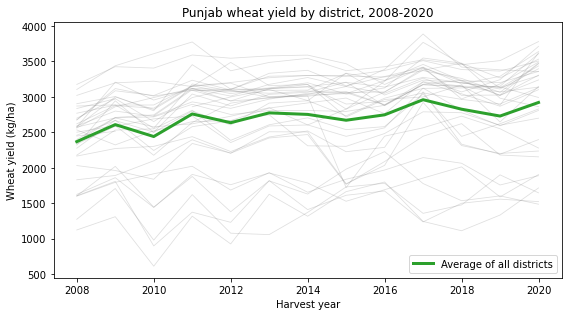

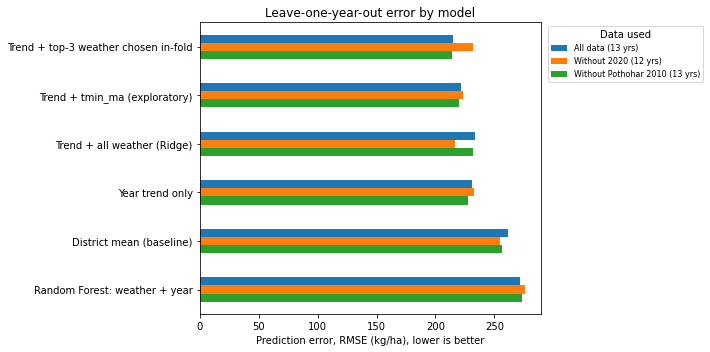

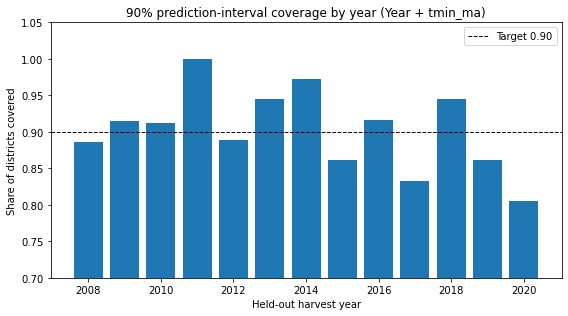

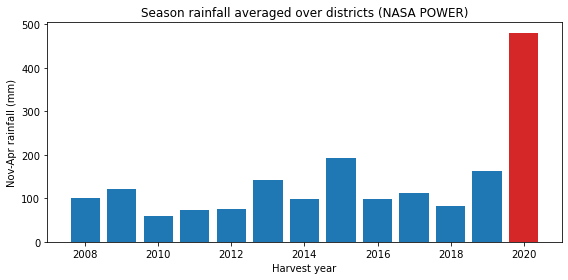

Saved: ['fig1_yield_trend.png', 'fig2_model_comparison.png', 'fig3_coverage_by_year.png', 'fig4_rainfall_by_year.png']


In [19]:
import matplotlib.pyplot as plt

Path("reports/figures").mkdir(parents=True, exist_ok=True)
mt = pd.read_csv("data/processed/wheat_model_table.csv")
res = pd.read_csv("reports/loyo_results.csv")
cov = pd.read_csv("reports/interval_coverage_by_year.csv").set_index("year")

# Figure 1: yield over time, one grey line per district
fig, ax = plt.subplots(figsize=(8, 4.5))
for d, g in mt.groupby("district"):
    ax.plot(g["harvest_year"], g["yield_kg_ha"], color="grey", alpha=0.25, lw=0.8)
avg = mt.groupby("harvest_year")["yield_kg_ha"].mean()
ax.plot(avg.index, avg.values, color="tab:green", lw=3, label="Average of all districts")
ax.set_xlabel("Harvest year"); ax.set_ylabel("Wheat yield (kg/ha)")
ax.set_title("Punjab wheat yield by district, 2008-2020")
ax.legend(); fig.tight_layout()
fig.savefig("reports/figures/fig1_yield_trend.png", dpi=200); plt.show()

# Figure 2: legend outside the plot
tab = res.pivot(index="model", columns="dataset", values="RMSE")
tab = tab.loc[tab.mean(axis=1).sort_values().index]
ax = tab.plot.barh(figsize=(10, 5))
ax.invert_yaxis()
ax.set_xlabel("Prediction error, RMSE (kg/ha), lower is better")
ax.set_ylabel("")
ax.set_title("Leave-one-year-out error by model")
ax.legend(title="Data used", fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.savefig("reports/figures/fig2_model_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

# Figure 3: legend in the free top-right corner
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(cov.index, cov["Blocked (year-out)"], color="tab:blue")
ax.axhline(0.90, color="black", ls="--", lw=1, label="Target 0.90")
ax.set_ylim(0.7, 1.05)
ax.set_xlabel("Held-out harvest year"); ax.set_ylabel("Share of districts covered")
ax.set_title("90% prediction-interval coverage by year (Year + tmin_ma)")
ax.legend(loc="upper right"); fig.tight_layout()
fig.savefig("reports/figures/fig3_coverage_by_year.png", dpi=200)
plt.show()

# Figure 4: season rainfall by year, showing why 2020 is treated as an extreme
rain = mt.groupby("harvest_year")["season_rain_mm"].mean()
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(rain.index, rain.values,
       color=["tab:red" if y == 2020 else "tab:blue" for y in rain.index])
ax.set_xlabel("Harvest year"); ax.set_ylabel("Nov-Apr rainfall (mm)")
ax.set_title("Season rainfall averaged over districts (NASA POWER)")
fig.tight_layout()
fig.savefig("reports/figures/fig4_rainfall_by_year.png", dpi=200); plt.show()

print("Saved:", sorted(p.name for p in Path("reports/figures").glob("*.png")))